In [1]:
import os
import json
import time
import hashlib
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import date
from pathlib import Path
from functools import reduce

def load_env(name=".env"):
    """Find .env in the working dir or any parent, load KEY=VALUE lines into os.environ."""
    for d in [Path.cwd(), *Path.cwd().parents]:
        f = d / name
        if f.is_file():
            for line in f.read_text(encoding="utf-8-sig").splitlines():
                line = line.strip()
                if not line or line.startswith("#") or "=" not in line:
                    continue
                k, v = line.split("=", 1)
                if not os.environ.get(k.strip()):
                    os.environ[k.strip()] = v.strip().strip('"').strip("'")
            return f
    return None

print(".env:", load_env() or "NOT FOUND (looked in cwd and its parents)", "| cwd:", Path.cwd())

DATA = Path("data"); DATA.mkdir(exist_ok=True)
CACHE_DIR = Path(".cache"); CACHE_DIR.mkdir(exist_ok=True)

# Steamboat Springs, CO -- center point for all basin distance filtering below
STEAMBOAT_LAT, STEAMBOAT_LON = 40.4850, -106.8317
RADIUS_MILES = 50  # widen if too few stations come back; the Yampa basin is large

def haversine_miles(lat1, lon1, lat2, lon2):
    R = 3958.8
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

def water_year(dates):
    """wy = year the water year ENDS in, e.g. 2024-10-01..2025-09-30 -> 2025. Matches co_streamflow.ipynb."""
    d = pd.to_datetime(dates)
    return d.dt.year + (d.dt.month >= 10).astype(int)

print(f"Basin center: Steamboat Springs ({STEAMBOAT_LAT}, {STEAMBOAT_LON}), radius {RADIUS_MILES} mi")

.env: NOT FOUND (looked in cwd and its parents) | cwd: /Users/aucklynnsacco/work/classes/GPGN/GPGN_438/gpgn438-design-drought-analysis/inital_data_exploration
Basin center: Steamboat Springs (40.485, -106.8317), radius 50 mi


In [4]:
streamflow_path = DATA / "co_streamflow_annual.csv"
enso_path = DATA / "enso_monthly.csv"

if not streamflow_path.exists():
    raise FileNotFoundError(
        f"{streamflow_path} not found. Run co_streamflow.ipynb first (it writes this file), then rerun this notebook.")
if not enso_path.exists():
    raise FileNotFoundError(
        f"{enso_path} not found. Run co_enso.ipynb first (it writes this file), then rerun this notebook.")

flow = pd.read_csv(streamflow_path)
flow = flow[flow["complete"]].copy()
flow["streamflow_pct_of_median"] = flow["volume_acre_ft"] / flow["volume_acre_ft"].median() * 100
flow_focus_site = flow["site"].iloc[0] if "site" in flow.columns and len(flow) else "unknown"
flow_wy = flow[["wy", "volume_acre_ft", "streamflow_pct_of_median", "peak_cfs", "min_7day_cfs"]].copy()
print(f"Streamflow: {len(flow_wy)} complete water years at {flow_focus_site}")

enso_monthly = pd.read_csv(enso_path, parse_dates=["date"])
enso_monthly["year"], enso_monthly["mon"] = enso_monthly["date"].dt.year, enso_monthly["date"].dt.month

def season_mean(frame, months, wy_offset, label):
    """Same logic as co_enso.ipynb §2: mean of specific calendar months, mapped to a water year,
    requiring all months present."""
    f = frame[frame["mon"].isin(months)].copy()
    f["wy"] = f["year"] + wy_offset
    g = f.groupby("wy")["anom"].agg(["mean", "count"])
    return g["mean"].where(g["count"] == len(months)).rename(label)

enso_fall = season_mean(enso_monthly, [10, 11, 12], 1, "enso_fall_anom")     # SON/OND/NDJ -> following WY
enso_winter = season_mean(enso_monthly, [1, 2, 3], 0, "enso_winter_anom")   # DJF/JFM/FMA -> same WY
enso_wy = pd.concat([enso_fall, enso_winter], axis=1).reset_index()
print(f"ENSO: {enso_wy['enso_winter_anom'].notna().sum()} water years with a winter value, "
      f"{enso_wy['enso_fall_anom'].notna().sum()} with a fall value")

Streamflow: 36 complete water years at USGS-09239500
ENSO: 77 water years with a winter value, 76 with a fall value


In [6]:
AWDB_BASE = "https://wcc.sc.egov.usda.gov/awdbRestApi/services/v1"

def awdb_get(endpoint, **params):
    """GET request to the AWDB REST API. Booleans must be lowercase 'true'/'false' -- the API
    silently ignores params it doesn't recognize rather than erroring, so a wrong param name or
    casing fails silently (returns unfiltered data) instead of raising."""
    clean_params = {k: (str(v).lower() if isinstance(v, bool) else v)
                    for k, v in params.items() if v is not None}
    resp = requests.get(f"{AWDB_BASE}/{endpoint}", params=clean_params, timeout=30)
    resp.raise_for_status()
    return resp.json()

all_co_sntl = pd.json_normalize(awdb_get(
    "stations", stationTriplets="*:CO:SNTL", activeOnly=True, elements="WTEQ"))
all_co_sntl["miles_to_steamboat"] = haversine_miles(
    STEAMBOAT_LAT, STEAMBOAT_LON, all_co_sntl["latitude"], all_co_sntl["longitude"])

yampa_snotel = (all_co_sntl[all_co_sntl["miles_to_steamboat"] <= RADIUS_MILES]
                 .sort_values("miles_to_steamboat").reset_index(drop=True))

print(f"{len(yampa_snotel)} SNOTEL stations with WTEQ within {RADIUS_MILES} mi of Steamboat Springs "
      f"(of {len(all_co_sntl)} statewide)")
yampa_snotel[["stationTriplet", "name", "elevation", "miles_to_steamboat", "beginDate"]].head(15)

21 SNOTEL stations with WTEQ within 50 mi of Steamboat Springs (of 118 statewide)


,stationTriplet,name,elevation,miles_to_steamboat,beginDate
0,457:CO:SNTL,Dry Lake,8240.0,4.278383,1979-10-01 00:00
1,825:CO:SNTL,Tower,10610.0,8.918138,1978-10-01 00:00
2,709:CO:SNTL,Rabbit Ears,9390.0,9.420589,1985-10-01 00:00
3,408:CO:SNTL,Columbine,9170.0,13.446158,1978-10-01 00:00
4,913:CO:SNTL,Buffalo Park,9240.0,21.636346,1995-09-01 00:00
5,940:CO:SNTL,Lost Dog,9350.0,23.254798,1998-08-01 00:00
6,1033:CO:SNTL,Zirkel,9320.0,24.738271,2002-08-14 00:00
7,426:CO:SNTL,Crosho,8960.0,24.959676,1985-10-01 00:00
8,1030:CO:SNTL,Arapaho Ridge,10960.0,25.432585,2002-08-01 00:00
9,1252:CO:SNTL,Elkhead Divide,8780.0,25.736882,2016-09-01 00:00


In [7]:
def get_swe_history(station_triplets, begin_date="1950-10-01", end_date=None):
    """Daily WTEQ for one or more stations, full history."""
    if end_date is None:
        end_date = date.today().isoformat()
    triplets = ",".join(station_triplets) if isinstance(station_triplets, (list, tuple)) else station_triplets
    raw = awdb_get("data", stationTriplets=triplets, elements="WTEQ", duration="DAILY",
                   beginDate=begin_date, endDate=end_date)
    rows = []
    for station in raw:
        triplet = station.get("stationTriplet")
        for elem in station.get("data", []):
            for point in elem.get("values", []):
                rows.append({"stationTriplet": triplet, "date": point.get("date"), "value": point.get("value")})
    df = pd.DataFrame(rows)
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"])
    return df

if yampa_snotel.empty:
    raise RuntimeError(f"No SNOTEL stations with WTEQ within {RADIUS_MILES} mi of Steamboat Springs. "
                       "Increase RADIUS_MILES and rerun from §1.")

swe_raw = get_swe_history(yampa_snotel["stationTriplet"].tolist())
print(f"{len(swe_raw)} daily SWE rows across {swe_raw['stationTriplet'].nunique()} stations")

swe_raw["wy"] = water_year(swe_raw["date"])

# Per station, per water year: peak SWE (the classic snowpack-severity metric) and the April 1 value
# (the classic water-supply-forecast reference date).
peak = swe_raw.groupby(["stationTriplet", "wy"])["value"].max().rename("peak_swe")
apr1 = (swe_raw[(swe_raw["date"].dt.month == 4) & (swe_raw["date"].dt.day == 1)]
        .groupby(["stationTriplet", "wy"])["value"].first().rename("apr1_swe"))
station_wy = pd.concat([peak, apr1], axis=1).reset_index()

# Normalize each station to its own median before averaging across stations -- stations at different
# elevations/aspects carry very different absolute SWE, so raw averaging would just reflect which
# station has deeper snow, not basin-wide anomaly.
station_wy["peak_swe_pct_of_median"] = station_wy.groupby("stationTriplet")["peak_swe"].transform(
    lambda s: s / s.median() * 100)

swe_wy = (station_wy.groupby("wy")
          .agg(swe_peak_pct_of_median=("peak_swe_pct_of_median", "mean"),
               n_stations=("stationTriplet", "nunique"))
          .reset_index())
print(f"{len(swe_wy)} water years with basin snowpack data (avg of {swe_wy['n_stations'].mean():.1f} stations)")
swe_wy.tail()

270514 daily SWE rows across 21 stations
50 water years with basin snowpack data (avg of 15.6 stations)


,wy,swe_peak_pct_of_median,n_stations
45,2023,126.794480,21
46,2024,104.378903,21
47,2025,90.976313,21
48,2026,55.120672,21
49,2027,2.678144,21


In [8]:
USGS_BASE = "https://api.waterdata.usgs.gov/ogcapi/v0"
USGS_API_KEY = os.environ.get("USGS_API_KEY") or None
GW_PARAM = "72019"  # depth to water level, ft below land surface
MIN_INTERVAL = 0.5 if USGS_API_KEY else 1.5
_last_call = [0.0]

def _get_json(url, query, headers, retries=8, use_cache=True, ttl_hours=6):
    key = hashlib.md5(f"{url}|{sorted((query or {}).items())}".encode()).hexdigest()
    cache_file = CACHE_DIR / f"{key}.json"
    if use_cache and cache_file.exists() and time.time() - cache_file.stat().st_mtime < ttl_hours * 3600:
        return json.loads(cache_file.read_text())
    for attempt in range(retries):
        wait = MIN_INTERVAL - (time.time() - _last_call[0])
        if wait > 0:
            time.sleep(wait)
        resp = requests.get(url, params=query, headers=headers, timeout=60)
        _last_call[0] = time.time()
        if resp.status_code in (429, 500, 502, 503, 504):
            delay = float(resp.headers.get("Retry-After", min(2 ** attempt * 2, 120)))
            print(f"  HTTP {resp.status_code}; sleeping {delay:.0f}s (attempt {attempt + 1}/{retries})")
            time.sleep(delay)
            continue
        if resp.status_code >= 400:
            raise requests.HTTPError(f"{resp.status_code} for {resp.url}\n{resp.text[:600]}", response=resp)
        js = resp.json()
        if use_cache:
            cache_file.write_text(json.dumps(js))
        return js
    resp.raise_for_status()

def ogc_get(collection, max_pages=100, **params):
    clean = {}
    for k, v in params.items():
        if v is None:
            continue
        if isinstance(v, bool):
            v = str(v).lower()
        elif isinstance(v, (list, tuple)):
            v = ",".join(map(str, v))
        clean[k] = v
    clean.setdefault("f", "json")
    clean.setdefault("limit", 10000)
    headers = {"X-Api-Key": USGS_API_KEY} if USGS_API_KEY else {}
    url, query, rows, pages = f"{USGS_BASE}/collections/{collection}/items", clean, [], 0
    while url and pages < max_pages:
        js = _get_json(url, query, headers)
        for feat in js.get("features", []):
            row = dict(feat.get("properties") or {})
            row["feature_id"] = feat.get("id")
            geom = feat.get("geometry") or {}
            if geom.get("type") == "Point":
                row["longitude"], row["latitude"] = geom["coordinates"][:2]
            rows.append(row)
        url = next((l["href"] for l in js.get("links", []) if l.get("rel") == "next"), None)
        query = None
        pages += 1
    return pd.DataFrame(rows)

def chunks(seq, n):
    seq = list(seq)
    for i in range(0, len(seq), n):
        yield seq[i:i + n]

co_gw_sites = ogc_get("monitoring-locations", state_name="Colorado", site_type_code="GW")
if "monitoring_location_id" not in co_gw_sites.columns:
    co_gw_sites["monitoring_location_id"] = co_gw_sites["feature_id"]
co_gw_sites["miles_to_steamboat"] = haversine_miles(
    STEAMBOAT_LAT, STEAMBOAT_LON, co_gw_sites["latitude"], co_gw_sites["longitude"])
yampa_wells = (co_gw_sites[co_gw_sites["miles_to_steamboat"] <= RADIUS_MILES]
               .dropna(subset=["latitude", "longitude"])
               .sort_values("miles_to_steamboat").reset_index(drop=True))
print(f"{len(yampa_wells)} groundwater wells within {RADIUS_MILES} mi of Steamboat Springs "
      f"(of {len(co_gw_sites)} statewide)")
show_gw = [c for c in ["monitoring_location_id", "monitoring_location_name", "miles_to_steamboat"]
           if c in yampa_wells.columns]
yampa_wells[show_gw].head(15)

787 groundwater wells within 50 mi of Steamboat Springs (of 28727 statewide)


,monitoring_location_id,monitoring_location_name,miles_to_steamboat
0,USGS-402949106491801,SB00608509BBC1,0.961206
1,USGS-403003106492201,SB00608405DDA,1.176558
2,USGS-402920106514701,SB00508431CCC,1.700646
3,USGS-403005106512101,SB00608406CCA1,1.722876
4,USGS-403030106513801,SB00608406BCB1,2.233833
5,USGS-403106106492001,SB00708433CBC1,2.348243
6,USGS-402941106523101,SB00608512BCA1,2.416506
7,USGS-402902106470401,SB00608514BBC1,2.452883
8,USGS-403017106523701,SB00608501CBC1,2.767014
9,USGS-402639106493601,SB00608429DDD,2.832455


In [9]:
def get_gw_history(site_ids, collection, begin="1950-01-01", end=None, per_request=25):
    """Historical depth-to-water for one or more wells. collection: 'field-measurements' (manual,
    long history) or 'daily' (sensor mean, shorter history but denser)."""
    if isinstance(site_ids, str):
        site_ids = [site_ids]
    stamped = collection == "field-measurements"
    b = begin + "T00:00:00Z" if stamped else begin
    e = (end or pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%dT%H:%M:%SZ")) if stamped else (end or date.today().isoformat())
    interval = f"{b}/{e}"
    frames = []
    for chunk in chunks(site_ids, per_request):
        try:
            f = ogc_get(collection, monitoring_location_id=chunk, parameter_code=GW_PARAM,
                       time=interval, skipGeometry=True)
        except requests.HTTPError as err:
            print(f"  {collection}: {err}")
            continue
        if not f.empty:
            frames.append(f)
    if not frames:
        return pd.DataFrame()
    df = pd.concat(frames, ignore_index=True)
    df["time"] = pd.to_datetime(df["time"], utc=True)
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    return df.dropna(subset=["value"])

if yampa_wells.empty:
    raise RuntimeError(f"No groundwater wells within {RADIUS_MILES} mi of Steamboat Springs. "
                       "Increase RADIUS_MILES and rerun from §2.")

well_ids = yampa_wells["monitoring_location_id"].tolist()
manual = get_gw_history(well_ids, "field-measurements")
daily = get_gw_history(well_ids, "daily")
print(f"{len(manual)} manual readings, {len(daily)} daily sensor readings")

gw_all = pd.concat([manual, daily], ignore_index=True) if (len(manual) or len(daily)) else pd.DataFrame()
if gw_all.empty:
    raise RuntimeError("No groundwater readings at all for these wells/parameter. "
                       "Check GW_PARAM against https://api.waterdata.usgs.gov/ogcapi/v0/collections/"
                       "time-series-metadata/items?monitoring_location_id=<ID>&f=json for one of the well IDs above.")

gw_all["wy"] = water_year(gw_all["time"])

# Depth-to-water anomaly per well: value minus that well's own long-term mean. Bigger = deeper = drier.
# This makes shallow and deep wells comparable before averaging across the basin.
gw_all["well_mean"] = gw_all.groupby("monitoring_location_id")["value"].transform("mean")
gw_all["anom_ft"] = gw_all["value"] - gw_all["well_mean"]

gw_wy = (gw_all.groupby("wy")
         .agg(gw_anom_ft=("anom_ft", "mean"), n_wells=("monitoring_location_id", "nunique"),
              n_readings=("anom_ft", "size"))
         .reset_index())
print(f"{len(gw_wy)} water years with basin groundwater data (avg of {gw_wy['n_wells'].mean():.1f} wells)")
gw_wy.tail()

1953 manual readings, 2199 daily sensor readings
20 water years with basin groundwater data (avg of 37.0 wells)


,wy,gw_anom_ft,n_wells,n_readings
15,1983,-4.451852,31,1219
16,1986,0.531763,36,287
17,1987,-1.413110,36,108
18,1988,19.088571,1,1
19,1993,0.000000,1,1


In [10]:
frames = [swe_wy[["wy", "swe_peak_pct_of_median", "n_stations"]],
          gw_wy[["wy", "gw_anom_ft", "n_wells"]],
          flow_wy,
          enso_wy]
joined = reduce(lambda l, r: l.merge(r, on="wy", how="outer"), frames).sort_values("wy").reset_index(drop=True)
joined["generated_utc"] = pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds")

core_vars = ["swe_peak_pct_of_median", "gw_anom_ft", "streamflow_pct_of_median", "enso_winter_anom"]
n_complete = joined.dropna(subset=core_vars).shape[0]
print(f"{len(joined)} water years total; {n_complete} with all four core variables present")

joined.to_csv(DATA / "co_joined_water_years.csv", index=False)
print("Wrote", DATA / "co_joined_water_years.csv")
joined.tail(10)

78 water years total; 1 with all four core variables present
Wrote data/co_joined_water_years.csv


,wy,swe_peak_pct_of_median,n_stations,gw_anom_ft,n_wells,volume_acre_ft,streamflow_pct_of_median,peak_cfs,min_7day_cfs,enso_fall_anom,enso_winter_anom,generated_utc
68,2018,93.841212,21.0,NaN,NaN,248934.80380,82.453580,2530.0,40.914286,-0.976667,-1.006667,2026-10-19T16:23:53+00:00
69,2019,111.482924,21.0,NaN,NaN,384754.96630,127.440695,3640.0,54.985714,0.740000,0.630000,2026-10-19T16:23:53+00:00
70,2020,108.782181,21.0,NaN,NaN,306682.62115,101.581135,3230.0,53.685714,0.220000,0.086667,2026-10-19T16:23:53+00:00
71,2021,84.043052,21.0,NaN,NaN,135252.88150,44.799217,1620.0,46.728571,-1.406667,-1.193333,2026-10-19T16:23:53+00:00
72,2022,90.752368,21.0,NaN,NaN,249944.80200,82.788117,2720.0,61.514286,-1.180000,-1.166667,2026-10-19T16:23:53+00:00
73,2023,126.794480,21.0,NaN,NaN,360610.61420,119.443467,3420.0,73.342857,-1.046667,-0.696667,2026-10-19T16:23:53+00:00
74,2024,104.378903,21.0,NaN,NaN,340136.13380,112.661795,3740.0,67.985714,1.373333,0.776667,2026-10-19T16:23:53+00:00
75,2025,90.976313,21.0,NaN,NaN,230339.29295,76.294271,2410.0,67.085714,-0.896667,-0.870000,2026-10-19T16:23:53+00:00
76,2026,55.120672,21.0,NaN,NaN,131472.33050,43.547002,1020.0,40.357143,-0.983333,-0.703333,2026-10-19T16:23:53+00:00
77,2027,2.678144,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-10-19T16:23:53+00:00


In [11]:
def rank_corr_perm(x, y, n_perm=5000, seed=0):
    ok = x.notna() & y.notna()
    n = int(ok.sum())
    if n < 4:
        return np.nan, np.nan, n
    rx, ry = x[ok].rank().values, y[ok].rank().values
    r = np.corrcoef(rx, ry)[0, 1]
    rng = np.random.default_rng(seed)
    hits = sum(abs(np.corrcoef(rx, rng.permutation(ry))[0, 1]) >= abs(r) for _ in range(n_perm))
    return r, (hits + 1) / (n_perm + 1), n

VAR_LABELS = {
    "swe_peak_pct_of_median": "Peak SWE (% of median)",
    "gw_anom_ft": "Groundwater anomaly (ft, + = deeper)",
    "streamflow_pct_of_median": "Streamflow volume (% of median)",
    "enso_fall_anom": "ENSO fall anomaly",
    "enso_winter_anom": "ENSO winter anomaly",
}
corr_vars = [v for v in VAR_LABELS if v in joined.columns]

r_mat = pd.DataFrame(index=corr_vars, columns=corr_vars, dtype=float)
p_mat = pd.DataFrame(index=corr_vars, columns=corr_vars, dtype=float)
n_mat = pd.DataFrame(index=corr_vars, columns=corr_vars, dtype="Int64")
for i, a in enumerate(corr_vars):
    for b in corr_vars[i:]:
        r, p, n = rank_corr_perm(joined[a], joined[b])
        r_mat.loc[a, b] = r_mat.loc[b, a] = r
        p_mat.loc[a, b] = p_mat.loc[b, a] = p
        n_mat.loc[a, b] = n_mat.loc[b, a] = n

print("Spearman r:"); print(r_mat.round(2).to_string())
print("\npermutation p-value:"); print(p_mat.round(3).to_string())
print("\nn (overlapping water years):"); print(n_mat.to_string())

Spearman r:
                          swe_peak_pct_of_median  gw_anom_ft  streamflow_pct_of_median  enso_fall_anom  enso_winter_anom
swe_peak_pct_of_median                      1.00       -0.04                      0.81           -0.14             -0.09
gw_anom_ft                                 -0.04        1.00                       NaN           -0.02             -0.09
streamflow_pct_of_median                    0.81         NaN                      1.00            0.02              0.04
enso_fall_anom                             -0.14       -0.02                      0.02            1.00              0.93
enso_winter_anom                           -0.09       -0.09                      0.04            0.93              1.00

permutation p-value:
                          swe_peak_pct_of_median  gw_anom_ft  streamflow_pct_of_median  enso_fall_anom  enso_winter_anom
swe_peak_pct_of_median                     0.000       0.927                     0.000           0.344             0.51

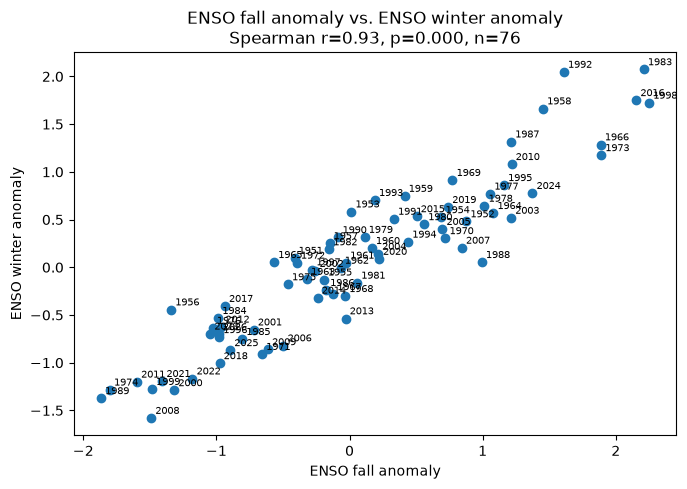

Strongest pair: enso_fall_anom vs enso_winter_anom  (r=0.93, p=0.000, n=76)


In [12]:
# Picks whichever off-diagonal pair has the strongest |r| with n >= 10, as a sanity-check plot.
best = None
for i, a in enumerate(corr_vars):
    for b in corr_vars[i + 1:]:
        r, p, n = r_mat.loc[a, b], p_mat.loc[a, b], n_mat.loc[a, b]
        if pd.notna(r) and n >= 10 and (best is None or abs(r) > abs(best[2])):
            best = (a, b, r, p, n)

if best is None:
    print("No pair with n >= 10 overlapping water years yet -- widen RADIUS_MILES or check data coverage.")
else:
    a, b, r, p, n = best
    d = joined.dropna(subset=[a, b])
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(d[a], d[b], c="tab:blue")
    for _, row in d.iterrows():
        ax.annotate(str(int(row["wy"])), (row[a], row[b]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_xlabel(VAR_LABELS[a]); ax.set_ylabel(VAR_LABELS[b])
    ax.set_title(f"{VAR_LABELS[a]} vs. {VAR_LABELS[b]}\nSpearman r={r:.2f}, p={p:.3f}, n={n}")
    plt.tight_layout(); plt.show()
    print(f"Strongest pair: {a} vs {b}  (r={r:.2f}, p={p:.3f}, n={n})")

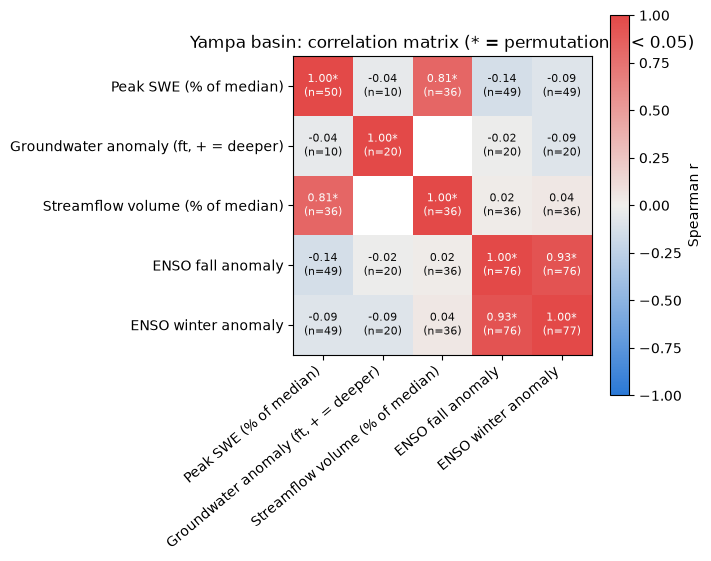

In [14]:
from matplotlib.colors import LinearSegmentedColormap

DIVERGING = LinearSegmentedColormap.from_list(
    "blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"], N=256
)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(r_mat.values.astype(float), cmap=DIVERGING, vmin=-1, vmax=1)
labels = [VAR_LABELS[v] for v in corr_vars]
ax.set_xticks(range(len(corr_vars))); ax.set_xticklabels(labels, rotation=40, ha="right")
ax.set_yticks(range(len(corr_vars))); ax.set_yticklabels(labels)
for i in range(len(corr_vars)):
    for j in range(len(corr_vars)):
        r, p, n = r_mat.iloc[i, j], p_mat.iloc[i, j], n_mat.iloc[i, j]
        if pd.isna(r):
            continue
        star = "*" if p < 0.05 else ""
        ax.text(j, i, f"{r:.2f}{star}\n(n={n})", ha="center", va="center", fontsize=8,
               color="#0b0b0b" if abs(r) < 0.5 else "#fcfcfb")
plt.colorbar(im, label="Spearman r")
ax.set_title("Yampa basin: correlation matrix (* = permutation p < 0.05)")
plt.tight_layout(); plt.show()

In [13]:
corr_long = []
for i, a in enumerate(corr_vars):
    for b in corr_vars[i + 1:]:
        corr_long.append({
            "var_a": a, "var_b": b,
            "label_a": VAR_LABELS[a], "label_b": VAR_LABELS[b],
            "spearman_r": None if pd.isna(r_mat.loc[a, b]) else round(float(r_mat.loc[a, b]), 3),
            "perm_p": None if pd.isna(p_mat.loc[a, b]) else round(float(p_mat.loc[a, b]), 4),
            "n": None if pd.isna(n_mat.loc[a, b]) else int(n_mat.loc[a, b]),
        })
corr_long_df = pd.DataFrame(corr_long).sort_values("spearman_r", key=lambda s: s.abs(), ascending=False)
corr_long_df.to_csv(DATA / "co_correlation_matrix.csv", index=False)

snapshot = {
    "generated_utc": pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds"),
    "basin": "Yampa River near Steamboat Springs, CO",
    "radius_miles": RADIUS_MILES,
    "n_snotel_stations": int(swe_wy["n_stations"].max()) if len(swe_wy) else 0,
    "n_gw_wells": int(gw_wy["n_wells"].max()) if len(gw_wy) else 0,
    "streamflow_site": flow_focus_site,
    "n_water_years_all_four": int(n_complete),
    "correlations": corr_long_df.to_dict("records"),
}
(DATA / "co_correlation_matrix.json").write_text(json.dumps(snapshot, indent=2, ensure_ascii=False))
print("Wrote", DATA / "co_correlation_matrix.csv", "and", DATA / "co_correlation_matrix.json")
corr_long_df

Wrote data/co_correlation_matrix.csv and data/co_correlation_matrix.json


,var_a,var_b,label_a,label_b,spearman_r,perm_p,n
9,enso_fall_anom,enso_winter_anom,ENSO fall anomaly,ENSO winter anomaly,0.931,0.0002,76
1,swe_peak_pct_of_median,streamflow_pct_of_median,Peak SWE (% of median),Streamflow volume (% of median),0.815,0.0002,36
2,swe_peak_pct_of_median,enso_fall_anom,Peak SWE (% of median),ENSO fall anomaly,-0.137,0.3437,49
3,swe_peak_pct_of_median,enso_winter_anom,Peak SWE (% of median),ENSO winter anomaly,-0.093,0.5139,49
6,gw_anom_ft,enso_winter_anom,"Groundwater anomaly (ft, + = deeper)",ENSO winter anomaly,-0.091,0.7049,20
8,streamflow_pct_of_median,enso_winter_anom,Streamflow volume (% of median),ENSO winter anomaly,0.044,0.7924,36
0,swe_peak_pct_of_median,gw_anom_ft,Peak SWE (% of median),"Groundwater anomaly (ft, + = deeper)",-0.042,0.9268,10
7,streamflow_pct_of_median,enso_fall_anom,Streamflow volume (% of median),ENSO fall anomaly,0.021,0.9002,36
5,gw_anom_ft,enso_fall_anom,"Groundwater anomaly (ft, + = deeper)",ENSO fall anomaly,-0.020,0.9414,20
4,gw_anom_ft,streamflow_pct_of_median,"Groundwater anomaly (ft, + = deeper)",Streamflow volume (% of median),NaN,NaN,1
